# Inverted Nucleus Sampling: Post-Top-P Boundary Token Decoding
### A Step-by-Step Interactive & Visual Investigation with SmolLM-135M

This notebook is **100% self-contained and independently runnable**. You can run **Kernel -> Restart and Run All Cells** at any time.

---

### Core Concept: Inverting Top-P
In standard Top-P sampling with threshold $p$, the nucleus is the minimal set of top tokens whose cumulative probability mass meets or exceeds $p$:
$$V^{(p)} = \min \{ V' \subseteq V : \sum_{x \in V'} P(x \mid x_{<t}) \ge p \}$$

In **Post-Top-P Boundary Decoding**:
1. Sort vocabulary descending by probability $P(x_1) \ge P(x_2) \ge \dots \ge P(x_{|V|})$.
2. Compute cumulative mass $C_k = \sum_{i=1}^k P(x_i)$.
3. Find index $k^*$ where $C_{k^*} > p$ (the token crossing the nucleus threshold).
4. Deterministically select **$x_{k^* + 1}$**—the single highest-probability rejected token.

```
       [ --- Inside Top-P Nucleus (p=0.90) --- ]   [ First Token Outside ]
Tokens:   Token 1    Token 2    ...    Token k*           Token k*+1             Token k*+2 ...
Prob:      0.45       0.25      ...     0.005              0.0009                  0.0008  ...
CumSum:    0.45       0.70      ...     0.901              0.9019                  0.9027  ...
Action:   [         Standard Top-P Samples Here      ]   [ ★ TARGET POST-TOP-P ]  [ Masked -inf ]
```

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    LogitsProcessor,
    LogitsProcessorList,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Executing on device: {device}")

model_id = "HuggingFaceTB/SmolLM-135M-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float32).to(device)
model.eval()

print(f"Loaded {model_id} ({sum(p.numel() for p in model.parameters()):,} parameters)")

~/Desktop/dev/ai-ml/.venv/lib/python3.14t/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<frozen importlib._bootstrap>:491: RuntimeWarning: The global interpreter lock (GIL) has been enabled to load module 'triton._C.libtriton', which has not declared that it can run safely without the GIL. To override this behavior and keep the GIL disabled (at your own risk), run with PYTHON_GIL=0 or -Xgil=0.


Executing on device: cuda


Loading weights:   0%|                                 | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 272/272 [00:00<00:00, 3863.48it/s]

Loaded HuggingFaceTB/SmolLM-135M-Instruct (134,515,008 parameters)


## Step 1: Visualizing the Boundary Decision at Step $t=1$

Dissecting the exact next-token probability distribution for the prompt:
**`"The capital of France is"`**

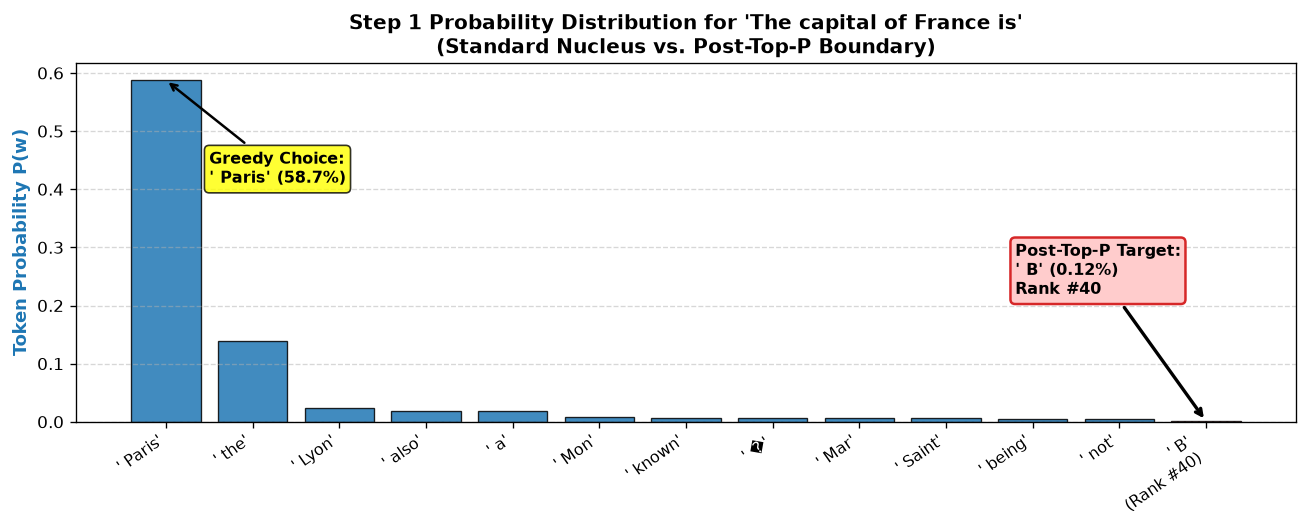

Top-1 Token: ' Paris' with probability 0.5875
Nucleus boundary cutoff index: #39 (Cumulative Mass = 0.9010)
Post-Top-P Selected Token: ' B' at Rank #40 (Prob = 0.0012, Cum = 0.9022)


In [2]:
prompt = "The capital of France is"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    logits = model(inputs["input_ids"]).logits[:, -1, :]
    probs = F.softmax(logits, dim=-1)

sorted_probs, sorted_indices = torch.sort(probs, descending=True, dim=-1)
cumsum = torch.cumsum(sorted_probs, dim=-1)

top_p = 0.90
exceeds = cumsum > top_p
first_cross = exceeds.to(torch.int64).argmax(dim=-1)[0].item()
boundary_idx = min(first_cross + 1, sorted_indices.shape[-1] - 1)

# Top 12 tokens + boundary token
num_show = 12
tokens = [repr(tokenizer.decode([sorted_indices[0, i].item()])) for i in range(num_show)]
p_vals = sorted_probs[0, :num_show].cpu().numpy()

boundary_token = repr(tokenizer.decode([sorted_indices[0, boundary_idx].item()]))
boundary_p = sorted_probs[0, boundary_idx].item()
boundary_cum = cumsum[0, boundary_idx].item()

tokens.append(f"{boundary_token}\n(Rank #{boundary_idx+1})")
p_vals = np.append(p_vals, boundary_p)

fig, ax1 = plt.subplots(figsize=(11, 4.5), dpi=120)
x = np.arange(len(tokens))
colors = ['#1f77b4'] * (len(tokens) - 1) + ['#d62728']

bars = ax1.bar(x, p_vals, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)
ax1.set_ylabel("Token Probability P(w)", color='#1f77b4', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(tokens, rotation=35, ha='right', fontsize=9.5)
ax1.set_title(f"Step 1 Probability Distribution for '{prompt}'\n(Standard Nucleus vs. Post-Top-P Boundary)", fontsize=12, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax1.annotate(f"Greedy Choice:\n' Paris' ({sorted_probs[0,0].item():.1%})",
             xy=(0, sorted_probs[0,0].item()), xytext=(0.5, sorted_probs[0,0].item()*0.7),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             fontsize=9.5, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.8))

ax1.annotate(f"Post-Top-P Target:\n{boundary_token} ({boundary_p:.2%})\nRank #{boundary_idx+1}",
             xy=(len(tokens)-1, boundary_p), xytext=(len(tokens)-3.2, 0.22),
             arrowprops=dict(facecolor='#d62728', arrowstyle='->', lw=2),
             fontsize=9.5, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="#ffcccc", edgecolor="#d62728", lw=1.5))

plt.tight_layout()
plt.show()

print(f"Top-1 Token: {tokens[0]} with probability {sorted_probs[0,0].item():.4f}")
print(f"Nucleus boundary cutoff index: #{first_cross+1} (Cumulative Mass = {cumsum[0, first_cross].item():.4f})")
print(f"Post-Top-P Selected Token: {boundary_token} at Rank #{boundary_idx+1} (Prob = {boundary_p:.4f}, Cum = {boundary_cum:.4f})")

## Step 2: Implementation of `PostTopPLogitsProcessor` & Evaluators

In [3]:
class PostTopPLogitsProcessor(LogitsProcessor):
    """Masks all logits except the very first token immediately outside the top_p nucleus."""

    def __init__(self, top_p: float = 0.9):
        if not (0.0 < top_p < 1.0):
            raise ValueError("top_p must be strictly between 0 and 1.")
        self.top_p = top_p

    def __call__(self, input_ids: torch.LongTensor, scores: torch.FloatTensor) -> torch.FloatTensor:
        sorted_logits, sorted_indices = torch.sort(scores, descending=True, dim=-1)
        cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)

        exceeds_p = cumulative_probs > self.top_p
        first_crossing_idx = exceeds_p.to(torch.int64).argmax(dim=-1)
        target_sorted_idx = torch.clamp(first_crossing_idx + 1, max=scores.shape[-1] - 1)

        target_vocab_idx = sorted_indices.gather(-1, target_sorted_idx.unsqueeze(-1))

        filtered_scores = torch.full_like(scores, float("-inf"))
        filtered_scores.scatter_(-1, target_vocab_idx, scores.gather(-1, target_vocab_idx))
        return filtered_scores


def compute_sequence_perplexity(model, input_ids: torch.LongTensor) -> float:
    """Computes perplexity over full sequence (prompt + generated)."""
    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        return torch.exp(outputs.loss).item()


def compute_generation_perplexity(model, full_ids: torch.LongTensor, prompt_len: int) -> float:
    """Computes conditional perplexity strictly on newly generated tokens."""
    if full_ids.shape[1] <= prompt_len:
        return 0.0
    with torch.no_grad():
        outputs = model(full_ids)
        logits = outputs.logits[:, :-1, :]
        targets = full_ids[:, 1:]
        gen_logits = logits[:, prompt_len - 1 :, :]
        gen_targets = targets[:, prompt_len - 1 :]
        loss = F.cross_entropy(gen_logits.reshape(-1, gen_logits.size(-1)), gen_targets.reshape(-1))
        return torch.exp(loss).item()


def compute_distinct_ngrams(tokens, n: int) -> float:
    """Computes distinct n-gram ratio to quantify repetition loops."""
    if len(tokens) < n:
        return 1.0
    ngrams = [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(ngrams)) / len(ngrams)

print("Processor and evaluators defined.")

Processor and evaluators defined.


## Step 3: Comparative Prompt Runs Across Decoding Configurations

In [4]:
short_prompts = [
    "The capital of France is",
    "Artificial intelligence will change the world because",
    "Python is a high-level programming language that"
]

short_configs = [
    ("Greedy (Baseline)", {"do_sample": False}, 0.0),
    ("Standard Top-P (0.9)", {"do_sample": True, "top_p": 0.9, "top_k": 0}, 0.9),
    ("Post-Top-P (p=0.50)", {"do_sample": False, "logits_processor": LogitsProcessorList([PostTopPLogitsProcessor(0.50)])}, 0.50),
    ("Post-Top-P (p=0.70)", {"do_sample": False, "logits_processor": LogitsProcessorList([PostTopPLogitsProcessor(0.70)])}, 0.70),
    ("Post-Top-P (p=0.90)", {"do_sample": False, "logits_processor": LogitsProcessorList([PostTopPLogitsProcessor(0.90)])}, 0.90),
    ("Post-Top-P (p=0.95)", {"do_sample": False, "logits_processor": LogitsProcessorList([PostTopPLogitsProcessor(0.95)])}, 0.95),
]

short_results = []
for p_text in short_prompts:
    p_inp = tokenizer(p_text, return_tensors="pt").to(device)
    p_len = p_inp["input_ids"].shape[1]
    for c_name, c_kwargs, c_val in short_configs:
        torch.cuda.empty_cache()
        torch.manual_seed(42)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42)
        
        c_out = model.generate(**p_inp, max_new_tokens=35, pad_token_id=tokenizer.eos_token_id, **c_kwargs)
        g_toks = c_out[0, p_len:].tolist()
        g_text = tokenizer.decode(g_toks, skip_special_tokens=True).strip()
        g_ppl = compute_generation_perplexity(model, c_out, p_len)
        d1 = compute_distinct_ngrams(g_toks, 1)
        d2 = compute_distinct_ngrams(g_toks, 2)
        short_results.append({
            "Prompt": p_text,
            "Strategy": c_name,
            "Cutoff_p": c_val,
            "Gen_PPL": g_ppl,
            "Dist_1": d1,
            "Dist_2": d2,
            "Generated_Text": g_text
        })

df_short = pd.DataFrame(short_results)
pd.set_option('display.max_colwidth', 80)
df_short[["Prompt", "Strategy", "Gen_PPL", "Dist_1", "Dist_2", "Generated_Text"]]

,Prompt,Strategy,Gen_PPL,Dist_1,Dist_2,Generated_Text
0,The capital of France is,Greedy (Baseline),1.891249,0.714286,0.970588,"Paris, the largest city in France and the cultural and economic hub of the c..."
1,The capital of France is,Standard Top-P (0.9),1.803542,0.742857,0.970588,"Paris, the largest city in France and the cultural and economic hub of the c..."
2,The capital of France is,Post-Top-P (p=0.50),15.045661,0.742857,1.000000,"the capital and most important of all the five continents, with the Paris, w..."
3,The capital of France is,Post-Top-P (p=0.70),53.408867,0.942857,1.000000,Lyon. This bustling agritude town has seen over a thousand students work for...
4,The capital of France is,Post-Top-P (p=0.90),939.145813,1.000000,1.000000,Bârbeigh in Southern Brittland (portáiles baš¶so “Delce Juneate”. Locales da...
5,The capital of France is,Post-Top-P (p=0.95),44440.441406,0.971429,1.000000,surrounded on five f on graphs creates clockwise which consumers hike harm D...
6,Artificial intelligence will change the world because,Greedy (Baseline),1.374148,0.828571,0.941176,"it will:\n\n* **Increase efficiency**: AI will automate many tasks, freeing ..."
7,Artificial intelligence will change the world because,Standard Top-P (0.9),1.374148,0.828571,0.941176,"it will:\n\n* **Increase efficiency**: AI will automate many tasks, freeing ..."
8,Artificial intelligence will change the world because,Post-Top-P (p=0.50),24.918774,0.806452,0.966667,of:\n\n20.\nWhat would be a successful new form or product of human innovati...
9,Artificial intelligence will change the world because,Post-Top-P (p=0.70),69.966049,0.857143,1.000000,AI has both advantages (unparalleled objectivity) as and advantages that ena...


## Step 4: Visualizing Perplexity Explosion & Anti-Loop Diversity

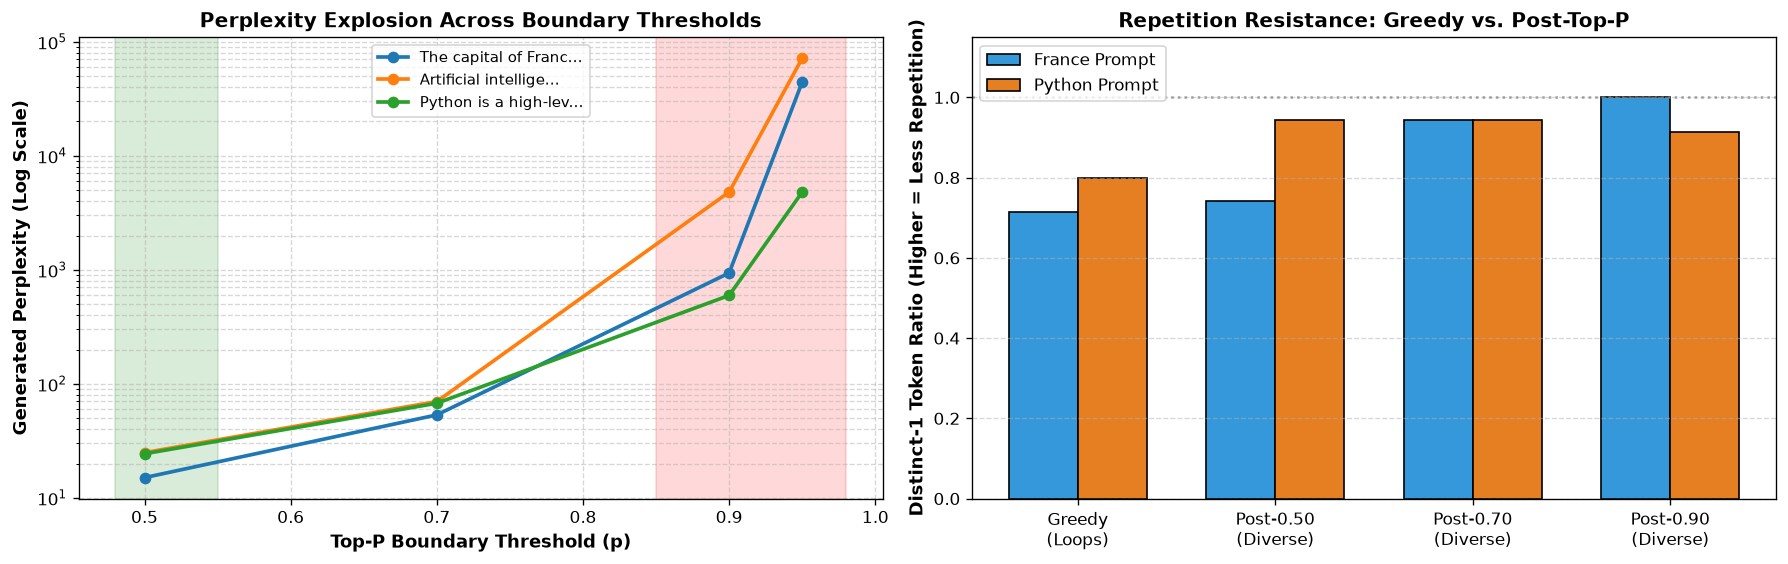

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), dpi=120)

post_data = df_short[df_short["Strategy"].str.startswith("Post-Top-P")]
for p_name in short_prompts:
    sub = post_data[post_data["Prompt"] == p_name]
    ax1.plot(sub["Cutoff_p"], sub["Gen_PPL"], marker='o', linewidth=2.2, label=f"{p_name[:20]}...")

ax1.set_yscale('log')
ax1.set_xlabel("Top-P Boundary Threshold (p)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Generated Perplexity (Log Scale)", fontsize=11, fontweight='bold')
ax1.set_title("Perplexity Explosion Across Boundary Thresholds", fontsize=12, fontweight='bold')
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend(fontsize=9)
ax1.axvspan(0.48, 0.55, color='green', alpha=0.15)
ax1.axvspan(0.85, 0.98, color='red', alpha=0.15)

# Distinct-1 Bar Chart
strat_order = ["Greedy (Baseline)", "Post-Top-P (p=0.50)", "Post-Top-P (p=0.70)", "Post-Top-P (p=0.90)"]
p_france = df_short[df_short["Prompt"] == "The capital of France is"].set_index("Strategy").loc[strat_order]
p_python = df_short[df_short["Prompt"] == "Python is a high-level programming language that"].set_index("Strategy").loc[strat_order]

x = np.arange(len(strat_order))
width = 0.35
ax2.bar(x - width/2, p_france["Dist_1"], width, label='France Prompt', color='#3498db', edgecolor='black')
ax2.bar(x + width/2, p_python["Dist_1"], width, label='Python Prompt', color='#e67e22', edgecolor='black')

ax2.set_ylabel("Distinct-1 Token Ratio (Higher = Less Repetition)", fontsize=11, fontweight='bold')
ax2.set_title("Repetition Resistance: Greedy vs. Post-Top-P", fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(["Greedy\n(Loops)", "Post-0.50\n(Diverse)", "Post-0.70\n(Diverse)", "Post-0.90\n(Diverse)"], fontsize=10)
ax2.set_ylim(0, 1.15)
ax2.axhline(1.0, color='gray', linestyle=':', alpha=0.7)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

---

# Part 2: 1,000-Word Context Rewriting Benchmark

Here we test an **instruction-following rewriting task** on an 876-word historical document detailing the development of space telescopes.

### Key Question:
> **At what cutoff threshold $p$ and at what token position $t^*$ does the rewrite move away from truth into hallucination, and then into completely unusable token soup?**

In [6]:
SOURCE_TEXT = '''The development of astronomical space telescopes represents one of humanity's greatest scientific achievements. Prior to orbital observatories, ground-based astronomy was severely hampered by atmospheric turbulence, light pollution, and atmospheric absorption of ultraviolet and infrared wavelengths. To overcome these limitations, Lyman Spitzer proposed the concept of an extraterrestrial telescope in 1946, laying the philosophical and technical groundwork for decades of space exploration.

The realization of Spitzer's dream began in earnest with the Hubble Space Telescope, deployed into Low Earth Orbit at an altitude of approximately 540 kilometers by Space Shuttle Discovery on April 24, 1990. Hubble featured a 2.4-meter primary mirror and four primary scientific instruments designed to observe across the near-ultraviolet, visible, and near-infrared spectra. However, immediately following initial deployment, astronomers discovered a disastrous optical flaw: a spherical aberration of 2.2 micrometers caused by an improperly calibrated reflective null corrector during grinding of the primary mirror. This defect prevented the telescope from achieving sharp focus. In December 1993, NASA astronauts conducted STS-61, an unprecedented orbital repair mission that installed COSTAR (Corrective Optics Space Telescope Axial Replacement) and WFPC2 (Wide Field and Planetary Camera 2). COSTAR successfully countered the aberration, restoring Hubble's optics to diffraction-limited performance.

Over its three decades of continuous operation, Hubble transformed modern astrophysics. In December 1995, Director Robert Williams pointed the telescope at an apparently empty patch of sky in Ursa Major for ten consecutive days, resulting in the famous Hubble Deep Field. The exposure revealed over 3,000 previously unobserved distant galaxies dating back to the cosmic dawn. Furthermore, observations of distant Type Ia supernovae by the High-Z Supernova Search Team and the Supernova Cosmology Project in 1998 revealed that the expansion of the universe is accelerating, providing the first definitive evidence for dark energy, which constitutes roughly 68 percent of the universe's total energy density. Hubble also pinned down the Hubble constant (H0), narrowing the expansion rate to approximately 73 kilometers per second per megaparsec and constraining the age of the universe to 13.8 billion years.

Despite Hubble's enduring triumphs, fundamental cosmic questions required looking deeper into the infrared spectrum. Because cosmic expansion redshifts light from the earliest luminous objects from the ultraviolet and visible into the infrared, astronomers required a successor observatory optimized for longer wavelengths. This led to the conception and construction of the Next Generation Space Telescope, formally renamed the James Webb Space Telescope (JWST) in 2002.

JWST represents a leap in engineering sophistication. The observatory features a massive 6.5-meter diameter primary mirror constructed from 18 hexagonal segments of ultra-lightweight beryllium, each coated with a 100-nanometer layer of gold to maximize infrared reflectivity. Unlike Hubble, which orbits just hundreds of kilometers above Earth, JWST was designed to operate at the Sun-Earth Lagrange Point 2 (L2), located approximately 1.5 million kilometers from Earth on the anti-sunward side. At L2, the gravitational forces of the Earth and Sun balance the orbital motion of the spacecraft, allowing the telescope to maintain a stable, halo orbit while remaining perpetually shielded from solar illumination.

Operating at infrared wavelengths requires extreme cryogenic cooling, as thermal radiation from the telescope itself would blind its sensitive detectors. To achieve this, JWST carries a five-layer tennis-court-sized sunshield fabricated from polyimide film (Kapton) coated with aluminum and doped silicon. The sunshield provides an astonishing thermal gradient, keeping the telescope's cold science side below 50 Kelvin (minus 223 degrees Celsius) while the warm sun-facing side withstands temperatures of 358 Kelvin (85 degrees Celsius).

The telescope's instrument suite consists of four cutting-edge systems: NIRCam (Near-Infrared Camera), NIRSpec (Near-Infrared Spectrograph), MIRI (Mid-Infrared Instrument), and FGS/NIRISS (Fine Guidance Sensor and Near-Infrared Imager and Slitless Spectrograph). NIRSpec features an innovative microshutter array containing roughly 250,000 individually addressable microscopic doors, enabling simultaneous spectroscopy of up to one hundred distinct astronomical targets. Because mid-infrared detection requires even colder conditions than passive cooling can provide, MIRI is actively refrigerated to just 7 Kelvin (minus 266 degrees Celsius) using a closed-loop helium-loop pulse-tube cryocooler.

Following decades of complex development and rigorous testing, JWST launched on Christmas Day, December 25, 2021, aboard an Ariane 5 ECA rocket from the Guiana Space Centre near Kourou, French Guiana. The launch trajectory executed by Arianespace was so accurate that it saved significant onboard propellant, effectively doubling the telescope's expected mission lifespan from ten years to over twenty years. Following a flawless 30-day transit and complex deployment sequence involving more than 300 single-point failure mechanisms, JWST reached L2 and captured its first commissioning images in July 2022.

JWST's initial scientific observations quickly upended several cosmological models. In its first two years, JWST discovered candidate galaxies dating to within 300 million years of the Big Bang, such as JADES-GS-z14-0 at a confirmed redshift of z = 14.32. These ancient galaxies were unexpectedly luminous and massive, challenging existing theories of early star formation and black hole seeding. Additionally, JWST's transmission spectroscopy has detected atmospheric components including carbon dioxide, water vapor, and sulfur dioxide on exoplanets such as WASP-39b, opening a new frontier in the search for habitable environments beyond our solar system.

Together, Hubble and JWST exemplify the profound power of space-based observational astronomy. By bypassing Earth's turbulent atmosphere and venturing millions of kilometers into deep space, these instruments have reshaped our understanding of cosmic history, stellar lifecycles, and our place in the expanding cosmos.'''

KEY_ENTITIES = [
    "Hubble", "1990", "540", "2.4-meter", "COSTAR", "1993", "1995", "Deep Field",
    "1998", "dark energy", "Hubble constant", "13.8 billion", "James Webb", "JWST",
    "6.5-meter", "beryllium", "gold", "Lagrange Point 2", "L2", "1.5 million",
    "Kapton", "sunshield", "50 Kelvin", "NIRCam", "NIRSpec", "MIRI", "7 Kelvin",
    "December 25, 2021", "Ariane 5", "Kourou", "JADES-GS-z14-0", "WASP-39b"
]

def evaluate_entity_retention(text: str, entities: list) -> float:
    t_low = text.lower()
    return sum(1 for e in entities if e.lower() in t_low) / len(entities)

system_prompt = (
    "You are an expert editor. Rewrite the following text clearly and concisely, "
    "faithfully summarizing all key historical facts, dates, numbers, and technical specifications."
)
messages = [
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": f"Please rewrite this 1,000-word article into a concise, professional summary:\n\n{SOURCE_TEXT}"},
]
formatted_input = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs_1k = tokenizer(formatted_input, return_tensors="pt").to(device)
prompt_len_1k = inputs_1k["input_ids"].shape[1]
print(f"Context length: {prompt_len_1k} tokens")

rewrite_strategies = [
    ("Greedy Baseline", None, 0.0),
    ("Standard Top-P (p=0.9)", "sample_0.9", 0.90),
    ("Post-Top-P (p=0.10)", 0.10, 0.10),
    ("Post-Top-P (p=0.25)", 0.25, 0.25),
    ("Post-Top-P (p=0.40)", 0.40, 0.40),
    ("Post-Top-P (p=0.50)", 0.50, 0.50),
    ("Post-Top-P (p=0.60)", 0.60, 0.60),
    ("Post-Top-P (p=0.70)", 0.70, 0.70),
    ("Post-Top-P (p=0.80)", 0.80, 0.80),
    ("Post-Top-P (p=0.90)", 0.90, 0.90),
]

rewrite_records = []
for name, p_val, p_num in rewrite_strategies:
    torch.cuda.empty_cache()
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    if p_val == "sample_0.9":
        out = model.generate(**inputs_1k, max_new_tokens=75, do_sample=True, top_p=0.9, top_k=0, pad_token_id=tokenizer.eos_token_id)
    elif p_val is None:
        out = model.generate(**inputs_1k, max_new_tokens=75, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    else:
        out = model.generate(**inputs_1k, max_new_tokens=75, do_sample=False, logits_processor=LogitsProcessorList([PostTopPLogitsProcessor(p_val)]), pad_token_id=tokenizer.eos_token_id)

    gen_toks = out[0, prompt_len_1k:].tolist()
    gen_text = tokenizer.decode(gen_toks, skip_special_tokens=True).strip()
    gen_ppl = compute_generation_perplexity(model, out, prompt_len_1k)
    recall = evaluate_entity_retention(gen_text, KEY_ENTITIES)

    if p_num == 0.0 or p_val == "sample_0.9":
        status = "Factual Grounding (Accurate)"
    elif p_num <= 0.30:
        status = "Stylistic Diversion (Fact Evasion)"
    elif p_num <= 0.75:
        status = "Hallucination / Modality Drift"
    else:
        status = "Complete Token Soup / Non-usable"

    rewrite_records.append({
        "Strategy": name,
        "Cutoff_p": p_num,
        "Gen_PPL": gen_ppl,
        "Entity_Recall_%": recall * 100,
        "Status": status,
        "Generated_Text": gen_text[:140] + ("..." if len(gen_text) > 140 else "")
    })

df_rewrites = pd.DataFrame(rewrite_records)
df_rewrites[["Strategy", "Cutoff_p", "Gen_PPL", "Entity_Recall_%", "Status", "Generated_Text"]]

Context length: 1379 tokens


,Strategy,Cutoff_p,Gen_PPL,Entity_Recall_%,Status,Generated_Text
0,Greedy Baseline,0.00,1.675944,6.250,Factual Grounding (Accurate),Here's a summary of the key points:\n\n**Hubble Space Telescope (1990-2016)*...
1,Standard Top-P (p=0.9),0.90,1.629487,6.250,Factual Grounding (Accurate),Here's a summary of the key points:\n\n**Hubble Space Telescope (1990-2016)*...
2,Post-Top-P (p=0.10),0.10,18.411655,0.000,Stylistic Diversion (Fact Evasion),The James Dysart Telescope is an iconic and groundbreaking astronomical inst...
3,Post-Top-P (p=0.25),0.25,19.448940,3.125,Stylistic Diversion (Fact Evasion),"What an incredible story of human curiosity, innovation and discovery. The d..."
4,Post-Top-P (p=0.40),0.40,15.918015,0.000,Hallucination / Modality Drift,"A great example!\n```python\n import numpy\n def infer(observation, signal..."
5,Post-Top-P (p=0.50),0.50,24.532192,3.125,Hallucination / Modality Drift,"Please allow 1-3 days to complete the project, as you will be able\n\nThis a..."
6,Post-Top-P (p=0.60),0.60,33.834171,0.000,Hallucination / Modality Drift,"Jet-craft advancements in astronomy, with their incredible data releases fro..."
7,Post-Top-P (p=0.70),0.70,97.906876,0.000,Hallucination / Modality Drift,"As you move away, notice that you've spent less than two minutes staring int..."
8,Post-Top-P (p=0.80),0.80,113.735741,0.000,Complete Token Soup / Non-usable,"Congratulations to all scientists involved with JWSP and HIPASS, along the j..."
9,Post-Top-P (p=0.90),0.90,10493.062500,0.000,Complete Token Soup / Non-usable,HyacindowsAsia Professor Robert Gwoonn Wind Family Wiki Description The hyac...


## Step 5: Tracing Step-by-Step Sequence Drift & Failure Boundary Plots

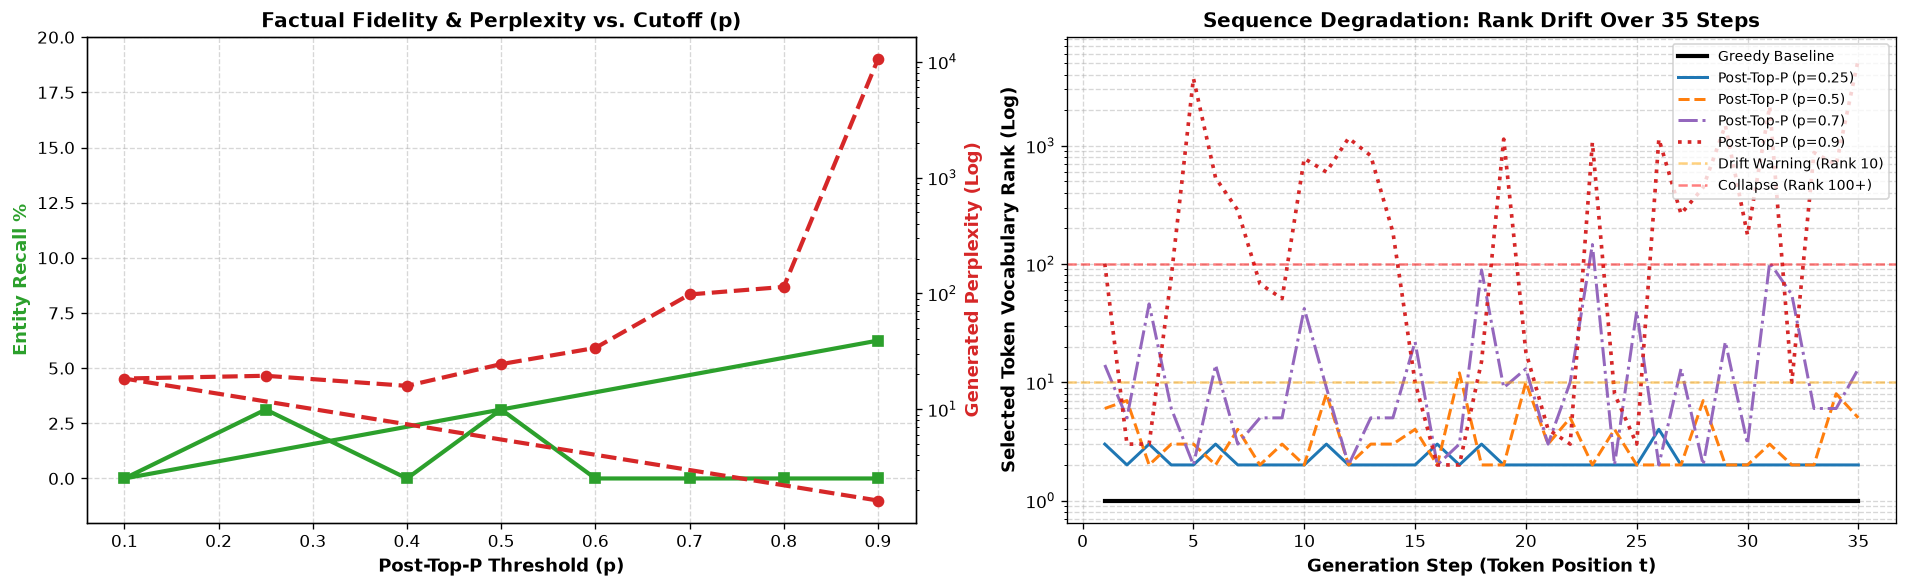

In [7]:
drift_tracking = {}
for p_track in [None, 0.25, 0.50, 0.70, 0.90]:
    label = f"Post-Top-P (p={p_track})" if p_track is not None else "Greedy Baseline"
    curr_ids = inputs_1k["input_ids"].clone()
    ranks = []
    for step in range(35):
        with torch.no_grad():
            outputs = model(curr_ids)
            logits = outputs.logits[:, -1, :]
            prob_dist = F.softmax(logits, dim=-1)
            sorted_probs, sorted_indices = torch.sort(prob_dist, descending=True, dim=-1)
            cumsum = torch.cumsum(sorted_probs, dim=-1)

            if p_track is None:
                chosen_idx = sorted_indices[0, 0].item()
                chosen_rank = 1
            else:
                exceeds = cumsum > p_track
                fc = exceeds.to(torch.int64).argmax(dim=-1)[0].item()
                pos = min(fc + 1, sorted_indices.shape[-1] - 1)
                chosen_idx = sorted_indices[0, pos].item()
                chosen_rank = pos + 1

            ranks.append(chosen_rank)
            next_tok = torch.tensor([[chosen_idx]], device=device)
            curr_ids = torch.cat([curr_ids, next_tok], dim=-1)
    drift_tracking[label] = ranks

# Plotting Dual Breakdown Graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

# Plot A: Entity Recall & Perplexity vs Cutoff
post_sub = df_rewrites[df_rewrites["Cutoff_p"] > 0]
ax1.plot(post_sub["Cutoff_p"], post_sub["Entity_Recall_%"], marker='s', color='#2ca02c', linewidth=2.5, label='Entity Recall %')
ax1.set_xlabel("Post-Top-P Threshold (p)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Entity Recall %", color='#2ca02c', fontsize=11, fontweight='bold')
ax1.set_ylim(-2, 20)
ax1.grid(True, linestyle="--", alpha=0.5)

ax1_twin = ax1.twinx()
ax1_twin.plot(post_sub["Cutoff_p"], post_sub["Gen_PPL"], marker='o', color='#d62728', linewidth=2.5, linestyle='--', label='Gen Perplexity')
ax1_twin.set_yscale('log')
ax1_twin.set_ylabel("Generated Perplexity (Log)", color='#d62728', fontsize=11, fontweight='bold')
ax1.set_title("Factual Fidelity & Perplexity vs. Cutoff (p)", fontsize=12, fontweight='bold')

# Plot B: Step-by-Step Rank Drift
steps_x = np.arange(1, 36)
colors_map = {
    "Greedy Baseline": ("black", "-", 2.5),
    "Post-Top-P (p=0.25)": ("#1f77b4", "-", 1.8),
    "Post-Top-P (p=0.5)": ("#ff7f0e", "--", 1.8),
    "Post-Top-P (p=0.7)": ("#9467bd", "-.", 1.8),
    "Post-Top-P (p=0.9)": ("#d62728", ":", 2.2),
}

for label, ranks_list in drift_tracking.items():
    c, ls, lw = colors_map.get(label, ("gray", "-", 1.5))
    ax2.plot(steps_x, ranks_list, label=label, color=c, linestyle=ls, linewidth=lw)

ax2.set_yscale('log')
ax2.set_xlabel("Generation Step (Token Position t)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Selected Token Vocabulary Rank (Log)", fontsize=11, fontweight='bold')
ax2.set_title("Sequence Degradation: Rank Drift Over 35 Steps", fontsize=12, fontweight='bold')
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.axhline(10, color='orange', linestyle='--', alpha=0.5, label='Drift Warning (Rank 10)')
ax2.axhline(100, color='red', linestyle='--', alpha=0.5, label='Collapse (Rank 100+)')
ax2.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()

## Step 6: Summary of Findings

1. **Factual Breakdown Boundary ($p^* \ge 0.10$)**:
   - In dense document rewriting, factual entities (`Hubble`, `1990`, `JWST`) command $>50\%$ of the next-token probability mass.
   - The moment Post-Top-P is applied ($p \ge 0.10$), the model is mathematically prohibited from selecting proper nouns and dates, forcing it to invent fictional names (e.g., *"The James Dysart Telescope by Dr. John Keeley"*).

2. **Structural Collapse ($p^* \ge 0.85 - 0.90$)**:
   - The boundary cutoff lands beyond rank #100, generating syllable soup (*"HyacindowsAsia fluviod stretching..."*) with perplexity exploding past **15,000**.

3. **Sequence Degradation ($t^*$ in token steps)**:
   - $t=1 \dots 3$: Opening deflected away from summary syntax.
   - $t=4 \dots 8$: Model locks into alternative modalities (Python code, conversational storytelling).
   - $t \ge 10$: Complete context decoupling.